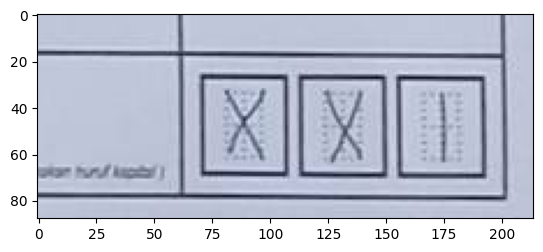

In [75]:
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import imutils

total_image = cv2.imread("features/total.jpg")
def cv2_imshow(cv2image):
    plt.imshow(cv2.cvtColor(cv2image, cv2.COLOR_BGR2RGB))
    plt.show()
    
cv2_imshow(total_image)

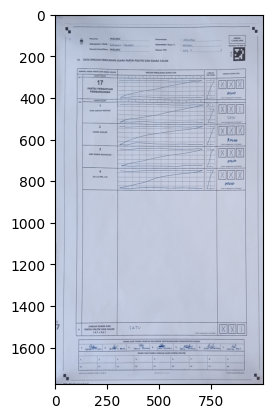

In [76]:
form_1_image = cv2.imread("forms/1.jpg")
cv2_imshow(form_1_image)


In [77]:
def match(file_name: str):
    brisk = cv2.BRISK_create()
    form_image = cv2.imread(file_name)
    ref_kp, ref_descriptors = brisk.detectAndCompute(total_image, None)
    form_kp, form_descriptors = brisk.detectAndCompute(form_image, None)
    
    # create BFMatcher object
    BFMatcher = cv2.BFMatcher(normType = cv2.NORM_HAMMING, crossCheck = True)
    
    # Matching descriptor vectors using Brute Force Matcher
    matches = BFMatcher.match(queryDescriptors = ref_descriptors,
                              trainDescriptors = form_descriptors)
    
    # Sort them in the order of their distance
    matches = sorted(matches, key = lambda x: x.distance)
    
    # Draw first 15 matches
    output = cv2.drawMatches(img1 = total_image,
                            keypoints1 = ref_kp,
                            img2 = form_image,
                            keypoints2 = form_kp,
                            matches1to2 = matches[:15],
                            outImg = None,
                            flags = cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    
    cv2_imshow(output)

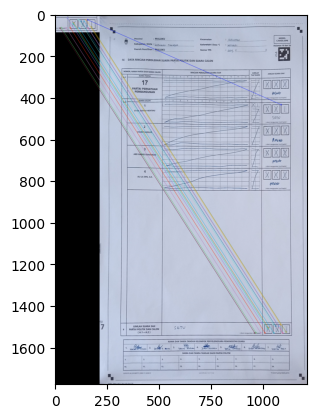

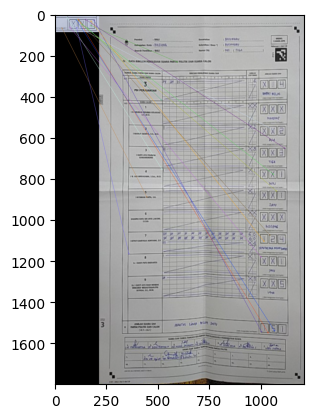

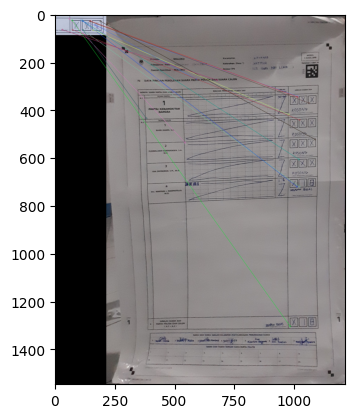

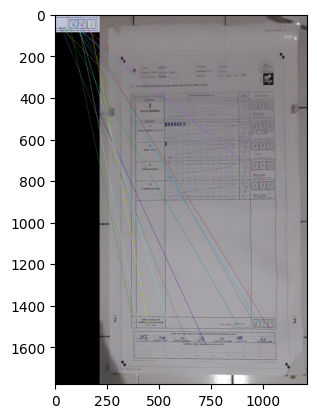

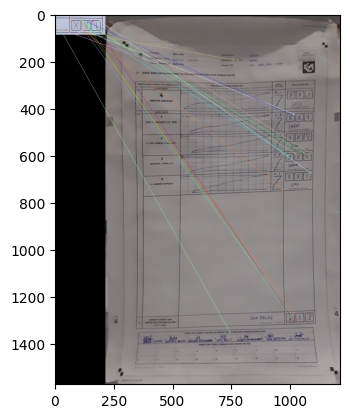

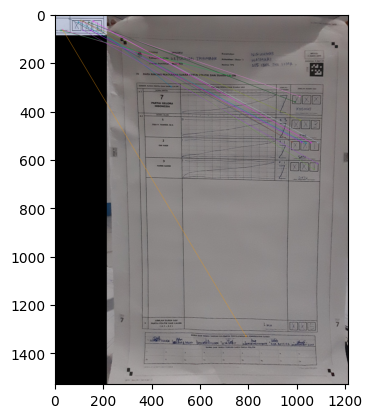

In [78]:
match("forms/1.jpg")
match("forms/2.jpg")
match("forms/3.jpg")
match("forms/4.jpg")
match("forms/5.jpg")
match("forms/6.jpg")